# **EN3160 Image Processing & Computer Vision - Assignment 03**


**Name : Meedeniya M.M.H**  
**Index No. : 230407K**

### **Github Repository** : https://github.com/manjarimeedeniya/EN3160-Assignment3

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt


### 2(a)

In [4]:
# Device configuration & seed
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# LeNet-5 needs 32x32: Pad MNIST (28x28) with 2 pixels on each side
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64
epochs = 10
learning_rate = 0.001

trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.features = nn.Sequential(
            # C1: Input (1, 32, 32) -> Output (6, 28, 28)
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1),
            nn.Tanh(),
            # S2: Output (6, 14, 14)
            nn.AvgPool2d(kernel_size=2, stride=2),
            # C3: Output (16, 10, 10)
            nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1),
            nn.Tanh(),
            # S4: Output (16, 5, 5)
            nn.AvgPool2d(kernel_size=2, stride=2),
            # C5: Output (120, 1, 1)
            nn.Conv2d(in_channels=16, out_channels=120, kernel_size=5, stride=1),
            nn.Tanh()
        )
        self.classifier = nn.Sequential(
            # F6: Linear mapping from 120 -> 84
            nn.Linear(120, 84),
            nn.Tanh(),
            # Output: 84 -> 10 classes
            nn.Linear(84, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)  # Flatten (batch_size, 120, 1, 1) to (batch_size, 120)
        logits = self.classifier(x)
        return logits

model = LeNet5().to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

train_losses, test_losses = [], []
train_accuracies, test_accuracies = [], []

for epoch in range(epochs):
    # --- Training Phase ---
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    for inputs, targets in trainloader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        total_train += targets.size(0)
        correct_train += (preds == targets).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100.0 * correct_train / total_train

    # --- Testing Phase ---
    model.eval()
    test_loss, correct_test, total_test = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in testloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            total_test += targets.size(0)
            correct_test += (preds == targets).sum().item()

    epoch_test_loss = test_loss / total_test
    epoch_test_acc = 100.0 * correct_test / total_test

    train_losses.append(epoch_train_loss)
    test_losses.append(epoch_test_loss)
    train_accuracies.append(epoch_train_acc)
    test_accuracies.append(epoch_test_acc)

    print(f"Epoch {epoch+1:02d}/10 | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.2f}%")

print(f"\nFinal Result after 10 epochs:")
print(f"Training Accuracy: {train_accuracies[-1]:.2f}%")
print(f"Test Accuracy:     {test_accuracies[-1]:.2f}%")

Using device: cpu
LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (classifier): Sequential(
    (0): Linear(in_features=120, out_features=84, bias=True)
    (1): Tanh()
    (2): Linear(in_features=84, out_features=10, bias=True)
  )
)
Epoch 01/10 | Train Loss: 0.2412 | Train Acc: 93.20% | Test Loss: 0.0861 | Test Acc: 97.31%
Epoch 02/10 | Train Loss: 0.0692 | Train Acc: 97.86% | Test Loss: 0.0520 | Test Acc: 98.35%
Epoch 03/10 | Train Loss: 0.0512 | Train Acc: 98.44% | Test Loss: 0.0466 | Test Acc: 98.51%
Epoch 04/10 | Train Loss: 0.0395 | Train Acc: 98.76% | Test Loss: 0.0461 | Test Acc: 98.57%
Epoch 05/10 | Train Loss: 0.0325 | Train Acc: 99.02% | Test Loss: 0.0486

### 2(b)

In [5]:
# 1. Dataset & DataLoader (Standard 28x28 normalized MNIST)
transform_modern = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64
epochs = 10
learning_rate = 0.001

trainset_modern = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform_modern)
testset_modern  = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform_modern)

trainloader_modern = torch.utils.data.DataLoader(trainset_modern, batch_size=batch_size, shuffle=True, num_workers=2)
testloader_modern  = torch.utils.data.DataLoader(testset_modern, batch_size=batch_size, shuffle=False, num_workers=2)

# 2. Modern 3-Layer CNN Architecture
class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()
        self.features = nn.Sequential(
            # Conv Layer 1: (1, 28, 28) -> (32, 28, 28) -> MaxPool -> (32, 14, 14)
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.1),

            # Conv Layer 2: (32, 14, 14) -> (64, 14, 14) -> MaxPool -> (64, 7, 7)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.2),

            # Conv Layer 3: (64, 7, 7) -> (128, 5, 5)
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=0),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Dropout2d(0.25)
        )

        # Guarantees fixed (4, 4) spatial output map before flattening
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.classifier = nn.Sequential(
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        logits = self.classifier(x)
        return logits

modern_model = ModernCNN().to(device)
print(modern_model)

# 3. Training Loop under Identical Conditions
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(modern_model.parameters(), lr=learning_rate)

modern_train_losses, modern_test_losses = [], []
modern_train_accuracies, modern_test_accuracies = [], []

print("\n--- Training Modern CNN (10 Epochs) ---")
for epoch in range(epochs):
    # Training
    modern_model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    for inputs, targets in trainloader_modern:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = modern_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        total_train += targets.size(0)
        correct_train += (preds == targets).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100.0 * correct_train / total_train

    # Testing
    modern_model.eval()
    test_loss, correct_test, total_test = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in testloader_modern:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = modern_model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            total_test += targets.size(0)
            correct_test += (preds == targets).sum().item()

    epoch_test_loss = test_loss / total_test
    epoch_test_acc = 100.0 * correct_test / total_test

    modern_train_losses.append(epoch_train_loss)
    modern_test_losses.append(epoch_test_loss)
    modern_train_accuracies.append(epoch_train_acc)
    modern_test_accuracies.append(epoch_test_acc)

    print(f"Epoch {epoch+1:02d}/10 | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.2f}%")

print(f"\nFinal Modern CNN Result after 10 epochs:")
print(f"Training Accuracy: {modern_train_accuracies[-1]:.2f}%")
print(f"Test Accuracy:     {modern_test_accuracies[-1]:.2f}%")

ModernCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.1, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.2, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): Dropout2d(p=0.25, inplace=False)
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): Sequential(
    (0): Linear(in_f

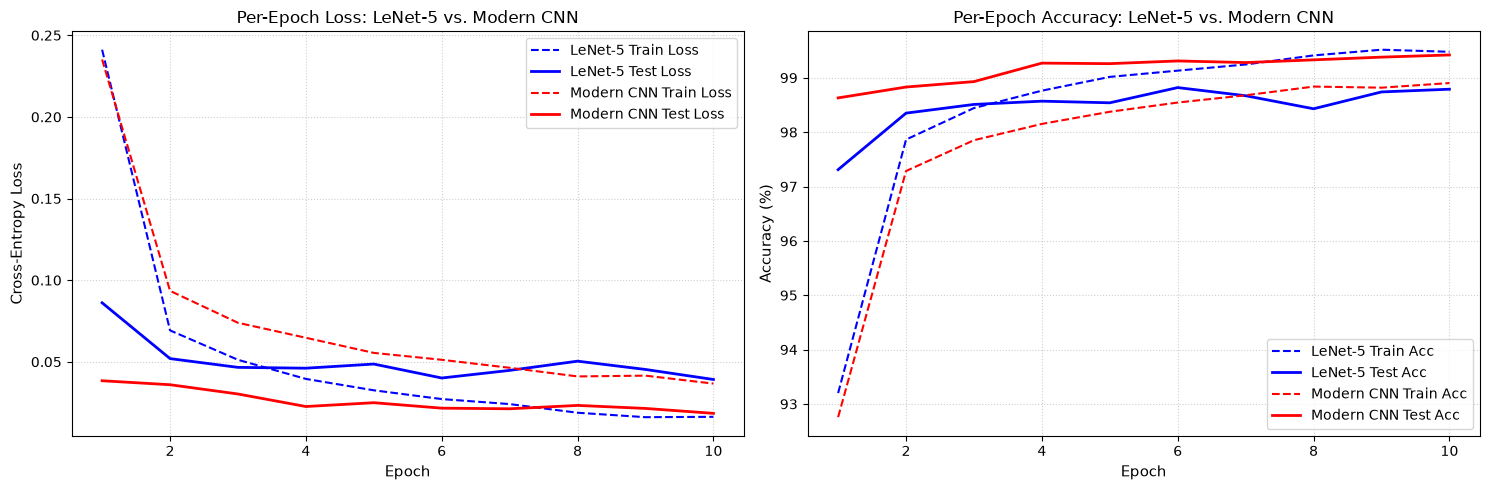

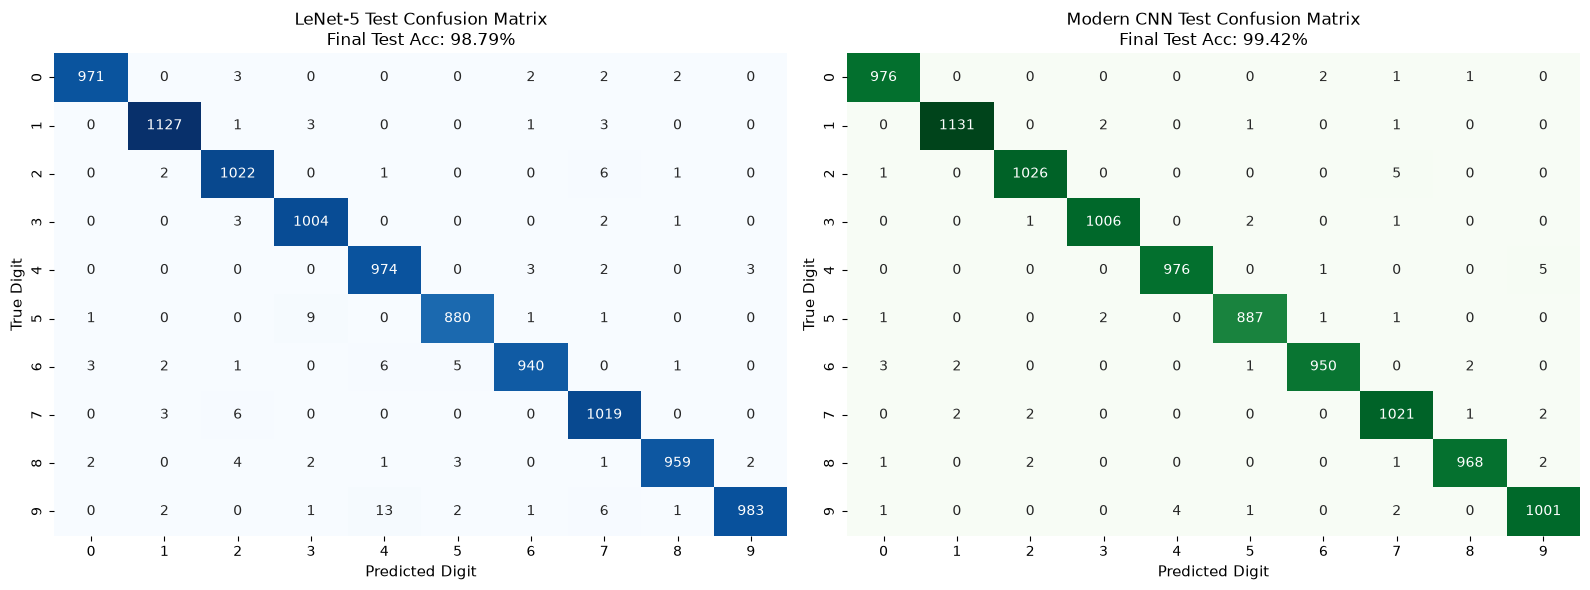

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def extract_predictions(model, dataloader):
    model.eval()
    all_targets = []
    all_predictions = []
    
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_predictions.extend(preds.cpu().numpy())
            all_targets.extend(targets.numpy())
            
    return np.array(all_targets), np.array(all_predictions)

y_true_lenet, y_pred_lenet = extract_predictions(model, testloader)
y_true_modern, y_pred_modern = extract_predictions(modern_model, testloader_modern)


epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(15, 5))

# Subplot 1: Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, 'b--', label='LeNet-5 Train Loss')
plt.plot(epochs_range, test_losses, 'b-', linewidth=2, label='LeNet-5 Test Loss')
plt.plot(epochs_range, modern_train_losses, 'r--', label='Modern CNN Train Loss')
plt.plot(epochs_range, modern_test_losses, 'r-', linewidth=2, label='Modern CNN Test Loss')
plt.title('Per-Epoch Loss: LeNet-5 vs. Modern CNN', fontsize=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Cross-Entropy Loss', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)

# Subplot 2: Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, 'b--', label='LeNet-5 Train Acc')
plt.plot(epochs_range, test_accuracies, 'b-', linewidth=2, label='LeNet-5 Test Acc')
plt.plot(epochs_range, modern_train_accuracies, 'r--', label='Modern CNN Train Acc')
plt.plot(epochs_range, modern_test_accuracies, 'r-', linewidth=2, label='Modern CNN Test Acc')
plt.title('Per-Epoch Accuracy: LeNet-5 vs. Modern CNN', fontsize=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

cm_lenet = confusion_matrix(y_true_lenet, y_pred_lenet)
cm_modern = confusion_matrix(y_true_modern, y_pred_modern)

class_names = [str(i) for i in range(10)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LeNet-5 Matrix
sns.heatmap(
    cm_lenet, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=class_names, 
    yticklabels=class_names, 
    ax=axes[0], 
    cbar=False
)
axes[0].set_title(f'LeNet-5 Test Confusion Matrix\nFinal Test Acc: {test_accuracies[-1]:.2f}%', fontsize=12)
axes[0].set_xlabel('Predicted Digit', fontsize=11)
axes[0].set_ylabel('True Digit', fontsize=11)

# Modern CNN Matrix
sns.heatmap(
    cm_modern, 
    annot=True, 
    fmt='d', 
    cmap='Greens', 
    xticklabels=class_names, 
    yticklabels=class_names, 
    ax=axes[1], 
    cbar=False
)
axes[1].set_title(f'Modern CNN Test Confusion Matrix\nFinal Test Acc: {modern_test_accuracies[-1]:.2f}%', fontsize=12)
axes[1].set_xlabel('Predicted Digit', fontsize=11)
axes[1].set_ylabel('True Digit', fontsize=11)

plt.tight_layout()
plt.show()

Question 3

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import numpy as np
import time
import os
import copy
import urllib.request
import zipfile

# As the first step I download dataset & setup data loaders
# Device configuration
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Download and unzip the hymenoptera dataset
dataset_url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
zip_path = "hymenoptera_data.zip"
data_dir = "hymenoptera_data"

if not os.path.exists(data_dir):
    urllib.request.urlretrieve(dataset_url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('.')

#  Standard ImageNet transformations
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=True, num_workers=2) for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

print(f"Classes: {class_names}")
print(f"Training images: {dataset_sizes['train']} | Validation images: {dataset_sizes['val']}")

Classes: ['ants', 'bees']
Training images: 244 | Validation images: 153


In [10]:
# Now I will perform training

def train_model(model, criterion, optimizer, scheduler, num_epochs=15):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1:02d}/{num_epochs}")
        print("-" * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train' and scheduler is not None:
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item() * 100)

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc*100:.2f}%")

            # Checkpoint the highest accuracy weights
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best Val Accuracy: {best_acc*100:.2f}%\n")

    model.load_state_dict(best_model_wts)
    return model, history

In [11]:
# Next will perform Fine Tuning
# Loading pretrained ResNet18
model_ft = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

model_ft, history_ft = train_model(
    model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=15
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\USER/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Epoch 01/15
----------
Train Loss: 0.5570 Acc: 72.95%
Val Loss: 0.5215 Acc: 76.47%

Epoch 02/15
----------
Train Loss: 0.3962 Acc: 81.97%
Val Loss: 0.3368 Acc: 88.24%

Epoch 03/15
----------
Train Loss: 0.5443 Acc: 79.10%
Val Loss: 0.2071 Acc: 92.81%

Epoch 04/15
----------
Train Loss: 0.4940 Acc: 81.15%
Val Loss: 0.3273 Acc: 91.50%

Epoch 05/15
----------
Train Loss: 0.4339 Acc: 81.97%
Val Loss: 0.5405 Acc: 85.62%

Epoch 06/15
----------
Train Loss: 0.3696 Acc: 84.02%
Val Loss: 0.5377 Acc: 84.31%

Epoch 07/15
----------
Train Loss: 0.5718 Acc: 82.79%
Val Loss: 0.3845 Acc: 83.01%

Epoch 08/15
----------
Train Loss: 0.3534 Acc: 86.89%
Val Loss: 0.2549 Acc: 90.85%

Epoch 09/15
----------
Train Loss: 0.3585 Acc: 83.20%
Val Loss: 0.2524 Acc: 90.85%

Epoch 10/15
----------
Train Loss: 0.2566 Acc: 89.75%
Val Loss: 0.2477 Acc: 89.54%

Epoch 11/15
----------
Train Loss: 0.2632 Acc: 88.11%
Val Loss: 0.2162 Acc: 92.81%

Epoch 12/15
----------
Train Loss: 0.3164 Acc: 86.07%
Val Loss: 0.2335 Acc: 

In [12]:
# Load fresh pretrained ResNet18
model_conv = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all convolutional backbone layers
for param in model_conv.parameters():
    param.requires_grad = False

# Replace final layer (requires_grad is True by default for new modules)
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)
model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Only parameters of the final layer are passed to the optimizer
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

model_conv, history_conv = train_model(
    model_conv, criterion, optimizer_conv, exp_lr_scheduler_conv, num_epochs=15
)

Epoch 01/15
----------
Train Loss: 0.6826 Acc: 64.34%
Val Loss: 0.2477 Acc: 88.89%

Epoch 02/15
----------
Train Loss: 0.7424 Acc: 65.57%
Val Loss: 0.3202 Acc: 85.62%

Epoch 03/15
----------
Train Loss: 0.4129 Acc: 78.69%
Val Loss: 0.2030 Acc: 90.85%

Epoch 04/15
----------
Train Loss: 0.5253 Acc: 79.10%
Val Loss: 0.1540 Acc: 95.42%

Epoch 05/15
----------
Train Loss: 0.4653 Acc: 79.51%
Val Loss: 0.2690 Acc: 88.89%

Epoch 06/15
----------
Train Loss: 0.3946 Acc: 83.61%
Val Loss: 0.1883 Acc: 93.46%

Epoch 07/15
----------
Train Loss: 0.3824 Acc: 83.20%
Val Loss: 0.2101 Acc: 94.77%

Epoch 08/15
----------
Train Loss: 0.4403 Acc: 79.10%
Val Loss: 0.1921 Acc: 94.12%

Epoch 09/15
----------
Train Loss: 0.4505 Acc: 80.74%
Val Loss: 0.1853 Acc: 94.12%

Epoch 10/15
----------
Train Loss: 0.2997 Acc: 85.66%
Val Loss: 0.1989 Acc: 94.12%

Epoch 11/15
----------
Train Loss: 0.3531 Acc: 85.66%
Val Loss: 0.1872 Acc: 93.46%

Epoch 12/15
----------
Train Loss: 0.3310 Acc: 86.48%
Val Loss: 0.1891 Acc: 

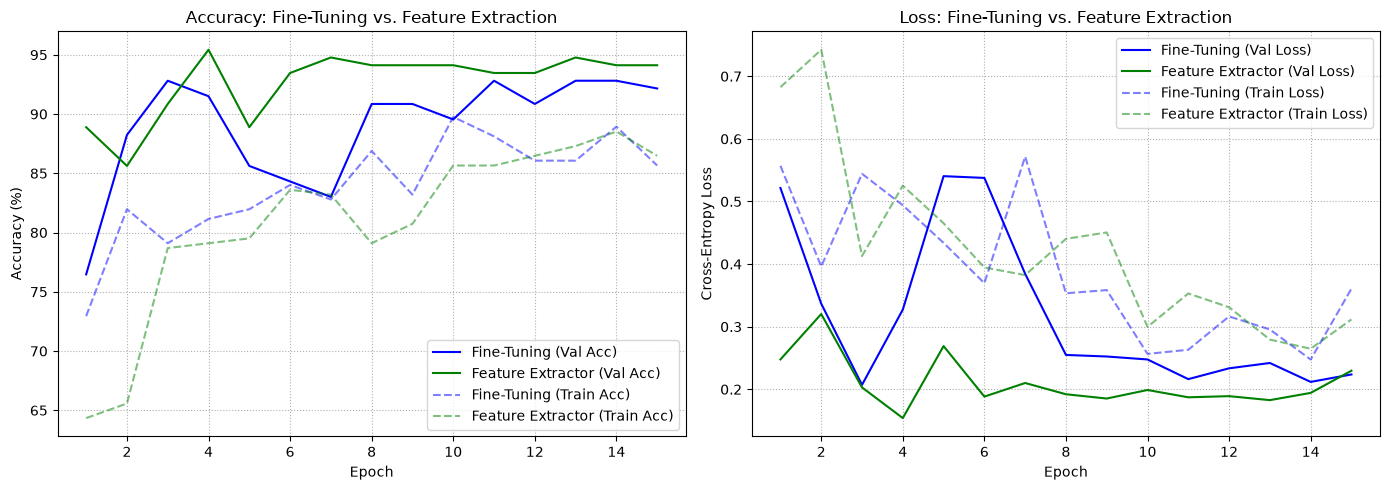

In [15]:
epochs_range = range(1, len(history_ft['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# Validation & Training Accuracy comparison
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_ft['val_acc'], 'b-', label='Fine-Tuning (Val Acc)')
plt.plot(epochs_range, history_conv['val_acc'], 'g-', label='Feature Extractor (Val Acc)')
plt.plot(epochs_range, history_ft['train_acc'], 'b--', alpha=0.5, label='Fine-Tuning (Train Acc)')
plt.plot(epochs_range, history_conv['train_acc'], 'g--', alpha=0.5, label='Feature Extractor (Train Acc)')
plt.title('Accuracy: Fine-Tuning vs. Feature Extraction', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True, linestyle=':')
plt.legend()

# Validation & Training Loss comparison
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_ft['val_loss'], 'b-', label='Fine-Tuning (Val Loss)')
plt.plot(epochs_range, history_conv['val_loss'], 'g-', label='Feature Extractor (Val Loss)')
plt.plot(epochs_range, history_ft['train_loss'], 'b--', alpha=0.5, label='Fine-Tuning (Train Loss)')
plt.plot(epochs_range, history_conv['train_loss'], 'g--', alpha=0.5, label='Feature Extractor (Train Loss)')
plt.title('Loss: Fine-Tuning vs. Feature Extraction', fontsize=12)
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True, linestyle=':')
plt.legend()

plt.tight_layout()
plt.show()